# Práctica: Clasificación de Imágenes mediante Redes Neuronales Convolucionales (CNN)
## Implementación de LeNet-5 sobre el Dataset MNIST

**Cátedra:** Visión por Computadora —
**FICH-UNL (Santa Fe, Argentina)**

### **Objetivos del Trabajo Práctico**
1. **Comprender la arquitectura LeNet-5:** Construir y entrenar la red convolucional histórica pionera en el procesamiento de caracteres manuscritos.
2. **Analizar el flujo de datos convolucional:** Observar la reducción espacial provocada por los filtros (Kernels) y capas de submuestreo (Pooling), entendiendo cómo la red pasa de características de bajo nivel a representaciones abstractas.
3. **Evaluar el rendimiento del modelo:** Interpretar las curvas de pérdida (*Loss*) y precisión (*Accuracy*) durante la fase de entrenamiento y validación.
4. **Comprobar el impacto del preprocesamiento en producción:** Experimentar con una pizarra interactiva en tiempo real para analizar cómo el centrado de masa, la escala y el grosor del trazo condicionan las predicciones del modelo fuera del dataset de prueba.

---

## Carga de Librerías

In [1]:
# Importar las librerías necesarias
import tensorflow as tf
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt
import numpy as np


## **Ejercicio 1: Carga de Datos y Definición de la Arquitectura LeNet-5**

En este ejercicio cargaremos el dataset **MNIST** (60,000 imágenes de entrenamiento y 10,000 de prueba de $28 \times 28$ píxeles en escala de grises).
Normalizaremos las intensidades al rango $[0, 1]$ dividiendo por $255.0$ y añadiremos la dimensión del canal ($28 \times 28 \times 1$).

A continuación, construiremos la arquitectura **LeNet-5** en Keras/TensorFlow. La red se compone de:
* **Capa Convolucional 1:** 6 filtros de $5 \times 5$ con activación ReLU. Reduce la dimensión espacial de $28 \times 28$ a $24 \times 24$.
* **Capa de Submuestreo 1:** *Average Pooling* de $2 \times 2$. Reduce la resolución espacial a $12 \times 12$.
* **Capa Convolucional 2:** 16 filtros de $5 \times 5$ con activación ReLU. Reduce la dimensión a $8 \times 8$.
* **Capa de Submuestreo 2:** *Average Pooling* de $2 \times 2$. Reduce la resolución a $4 \times 4$.
* **Aplanamiento (*Flatten*):** Convierte el tensor de $4 \times 4 \times 16$ en un vector $1\text{D}$ de $256$ elementos.
* **Capas Densas Completely Conectadas:** Capas ocultas de $120$ y $84$ neuronas (ReLU) y una capa de salida de $10$ neuronas con función de activación **Softmax**.

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step


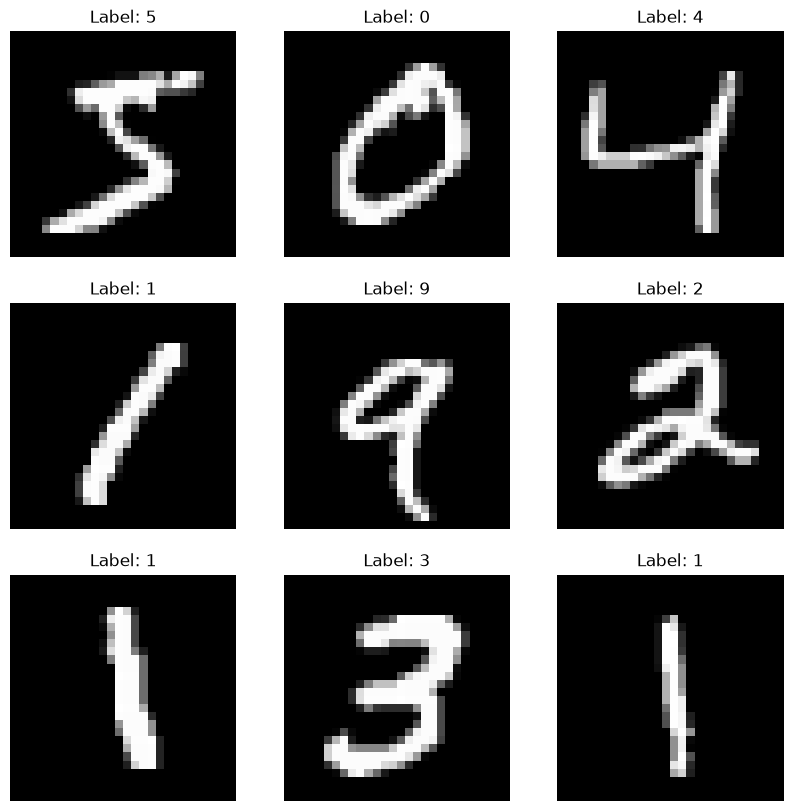

In [2]:
# Cargar el dataset MNIST desde keras
mnist = tf.keras.datasets.mnist
(X_train, y_train), (X_test, y_test) = mnist.load_data()

# Normalizar los valores de las imágenes (de 0-255 a 0-1)
X_train = X_train.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0

# Redimensionar las imágenes para que tengan un solo canal (grayscale) en lugar de 28x28
X_train = np.expand_dims(X_train, axis=-1)
X_test = np.expand_dims(X_test, axis=-1)

# Visualizar algunas imágenes de ejemplo del dataset
plt.figure(figsize=(10, 10))
for i in range(9):
    plt.subplot(3, 3, i+1)
    plt.imshow(X_train[i].reshape(28, 28), cmap='gray')
    plt.title(f"Label: {y_train[i]}")
    plt.axis('off')
plt.show()

In [3]:
# Definir la arquitectura LeNet con capas convolucionales y de pooling correctas
model = models.Sequential()

# Agregar la capa de entrada explícita para evitar una advertencia de tamaños
model.add(layers.Input(shape=(28, 28, 1)))

# Capa Convolucional 1
model.add(layers.Conv2D(6, kernel_size=(5, 5), activation='relu')) #convolucion con un kernel 5x5 con 6 capas
model.add(layers.AveragePooling2D(pool_size=(2, 2))) #pooling a mitad

# Capa Convolucional 2
model.add(layers.Conv2D(16, kernel_size=(5, 5), activation='relu'))
model.add(layers.AveragePooling2D(pool_size=(2, 2)))

# Flatten para convertir a 1D
model.add(layers.Flatten())

# Capa densa completamente conectada
model.add(layers.Dense(120, activation='relu')) #dense es fc

# Capa densa 2
model.add(layers.Dense(84, activation='relu'))

# Capa de salida con 10 neuronas (una por cada dígito)
model.add(layers.Dense(10, activation='softmax'))

# Compilar el modelo
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

# Resumen de la arquitectura
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 24, 24, 6)      │           156 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d               │ (None, 12, 12, 6)      │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 8, 8, 16)       │         2,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_1             │ (None, 4, 4, 16)       │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 120)            │        30,840 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 84)             │        10,164 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           850 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 44,426 (173.54 KB)

 Trainable params: 44,426 (173.54 KB)

 Non-trainable params: 0 (0.00 B)

### 💡 Reflexión - Ejercicio 1: Arquitectura y Extracción de Características

1. **Reducción de la Dimensión Espacial:**
  * ¿Por qué la primera capa convolucional de $6$ filtros de $5 \times 5$ sin relleno (*valid padding*) reduce la dimensión de la imagen de $28 \times 28$ a $24 \times 24$?
  * Explica la fórmula matemática utilizada para calcular el tamaño del mapa de características de salida en función del tamaño de entrada ($N$), tamaño del kernel ($K$), zancada ($S$) y relleno ($P$).

2. **Compartición de Pesos vs. Capas Densas:**
  * ¿Qué ventaja conceptual y computacional ofrece utilizar filtros convolucionales compartidos de $5 \times 5$ en las primeras capas en lugar de aplanar directamente la imagen de $784$ píxeles y conectarla a una capa totalmente conectada (*Dense*) desde el inicio?

3. **Impacto de la Normalización de Píxeles:** En la etapa de carga dividimos los píxeles por $255.0$.
  * Justifica qué ocurriría con la magnitud de los gradientes durante la retropropagación (*backpropagation*) y la estabilidad del entrenamiento si alimentáramos la red con valores enteros en el rango original $[0, 255]$.

**Enlaces y Lecturas Sugeridas:**
- [Gradient-Based Learning Applied to Document Recognition (LeCun et al., 1998)](https://www.semanticscholar.org/paper/Gradient-based-learning-applied-to-document-LeCun-Bottou/162d958ff885f1462aeda91cd72582323fd6a1f4)
- [TensorFlow Keras Conv2D API Documentation](https://www.tensorflow.org/api_docs/python/tf/keras/layers/Conv2D)
- [CS231n: Convolutional Neural Networks for Visual Recognition (Stanford)](https://cs231n.github.io/)

---

## **Ejercicio 2: Entrenamiento, Optimización y Análisis de Métricas**

En este ejercicio utilizaremos el optimizador **Adam** y la función de pérdida **Sparse Categorical Crossentropy** (adecuada cuando las etiquetas de clase son enteros simples \\(\{0, 1, \dots, 9\}\\)).

Entrenaremos el modelo durante **5 épocas** con un tamaño de lote (*batch size*) predeterminado, utilizando el conjunto de prueba de 10,000 imágenes como validación (`validation_data`).

Al finalizar el entrenamiento, graficaremos las curvas de pérdida (*Loss*) y precisión (*Accuracy*) tanto para el conjunto de entrenamiento como para el de validación para analizar el comportamiento del modelo.

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - accuracy: 0.9221 - loss: 0.2534 - val_accuracy: 0.9671 - val_loss: 0.0996
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9754 - loss: 0.0818 - val_accuracy: 0.9822 - val_loss: 0.0575
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9822 - loss: 0.0578 - val_accuracy: 0.9867 - val_loss: 0.0494
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9858 - loss: 0.0440 - val_accuracy: 0.9841 - val_loss: 0.0514
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9880 - loss: 0.0374 - val_accuracy: 0.9868 - val_loss: 0.0440
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9868 - loss: 0.0440

Precisión en test: 0.9868


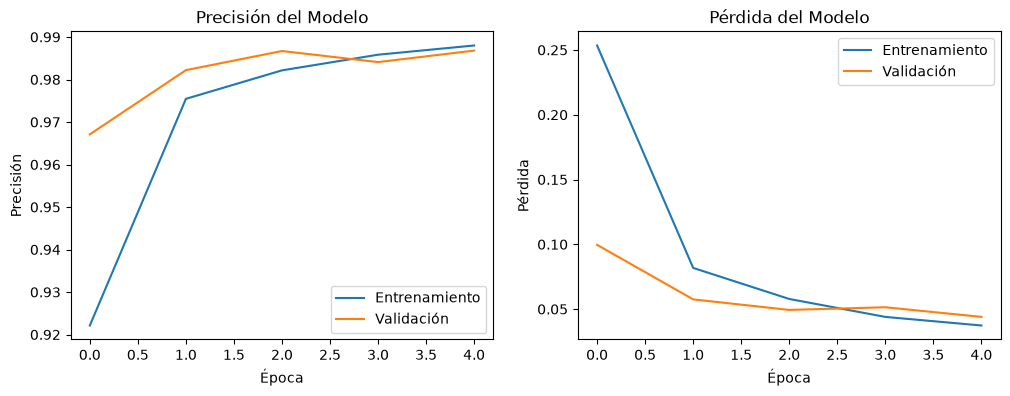

In [4]:
# Entrenar el modelo
history = model.fit(X_train, y_train, epochs=5, batch_size=32, validation_data=(X_test, y_test))

# Evaluar el modelo en el conjunto de prueba
test_loss, test_acc = model.evaluate(X_test, y_test)
print(f'\nPrecisión en test: {test_acc:.4f}')

# Graficar la precisión y la pérdida durante el entrenamiento
plt.figure(figsize=(12, 4))

# Gráfico de Precisión
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Entrenamiento')
plt.plot(history.history['val_accuracy'], label='Validación')
plt.title('Precisión del Modelo')
plt.xlabel('Época')
plt.ylabel('Precisión')
plt.legend()

# Gráfico de Pérdida
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Entrenamiento')
plt.plot(history.history['val_loss'], label='Validación')
plt.title('Pérdida del Modelo')
plt.xlabel('Época')
plt.ylabel('Pérdida')
plt.legend()

plt.show()

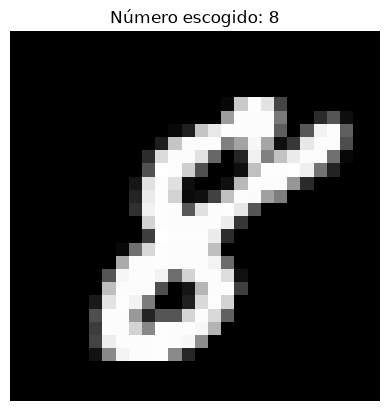

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step
Etiqueta verdadera: 8
Etiqueta predicha: 8


In [5]:
# Seleccionar una imagen de test al azar
random_index = np.random.randint(0, len(X_test))
test_image = X_test[random_index]
test_label = y_test[random_index]

# Mostrar la imagen
plt.imshow(test_image.reshape(28, 28), cmap='gray')
plt.title(f"Número escogido: {test_label}")
plt.axis('off')
plt.show()

# Realizar la predicción con la red (inferencia)
prediction = model.predict(np.expand_dims(test_image, axis=0))
predicted_label = np.argmax(prediction)

print(f"Etiqueta verdadera: {test_label}")
print(f"Etiqueta predicha: {predicted_label}")

# Puedes agregar más código para evaluar la precisión de la predicción
# (por ejemplo, comparando predicted_label con test_label)

### 💡 Reflexión Guía - Ejercicio 2: Entrenamiento, Métricas y Evaluación del Modelo

1. **Diagnóstico de Sobreajuste (*Overfitting*):** Al analizar los gráficos de *Accuracy* y *Loss* a lo largo de las 5 épocas,
  * ¿qué comportamiento de las curvas de entrenamiento frente a validación indicaría que el modelo está memorizando el dataset?
  * ¿Se observa este fenómeno en la red LeNet-5 entrenada?

2. **Selección de la Función de Pérdida:**
  * Explica la diferencia matemática y de formato de datos entre utilizar `sparse_categorical_crossentropy` y `categorical_crossentropy`.
  * ¿Qué transformación previa en las etiquetas \\(y\\) requeriría esta última?

3. **Comportamiento del Optimizador Adam:**
  * ¿Qué ventajas ofrece el optimizador adaptable `Adam` frente al descenso de gradiente estocástico (SGD) tradicional al actualizar los \\(44,426\\) parámetros entrenables de esta red?

**Enlaces y Lecturas Sugeridas:**
- [Deep Learning Book - Optimization for Training Deep Models (Goodfellow et al.)](https://www.deeplearningbook.org/contents/optimization.html)
- [Adam: A Method for Stochastic Optimization (Kingma & Ba, 2014)](https://arxiv.org/abs/1412.6980)
- [TensorFlow Guide: Model Training and Evaluation](https://www.tensorflow.org/guide/keras/training_with_built_in_methods)

---

## **Ejercicio 3: Inferencia Interactiva, Preprocesamiento de Dominio y Salidas Fuera de Distribución (OOD)**

En este ejercicio evaluaremos el modelo entrenado en un escenario real de producción utilizando una **pizarra interactiva** integrada en Colab.

### Paso 1: preprocesar como MNIST

Para que la red pueda clasificar correctamente un trazo dibujado a mano alzada, es fundamental aplicar un preprocesamiento que iguale la distribución estadística del dataset MNIST original:

1. **Extracción y escalado:** La imagen dibujada se convierte a escala de grises y se escala para encajar en una caja delimitadora de \\(20 \times 20\\) píxeles preservando la relación de aspecto.
2. **Centrado por centro de masa:** La región de \\(20 \times 20\\) píxeles se posiciona en el centro de una matriz de \\(28 \times 28\\) píxeles calculando el centro de masa (`center_of_mass`) de las intensidades.
3. **Normalización:** Los valores de gris se escalan al intervalo \\([0.0, 1.0]\\).

---

### Paso 2: conectar la pizarra con el modelo

Se debe llamar a la `pizarra` cada vez que se termina un trazo. Ésta recibe el dibujo como imagen PNG, lo preprocesa y devuelve las probabilidades de cada dígito junto con la imagen de `28×28` que efectivamente "ve" la red.

---

### Paso 3: usar la pizarra

Ahora se puede dibujar un dígito con el mouse (o con el dedo en una pantalla táctil). La predicción se actualiza al soltar cada trazo como mencionamos. A la derecha se mostrará la imagen de `28×28` que recibe la red después del preprocesamiento.


In [6]:
# Preprocesamiento como MNIST
from scipy import ndimage
from PIL import Image

def preprocesar_como_mnist(img):
    """Recibe una imagen en escala de grises (uint8, trazo claro sobre fondo oscuro)
    y devuelve un array 28x28 con valores entre 0 y 1, o None si está vacía."""
    # 1. Recortar al rectángulo que contiene el trazo
    filas, cols = np.nonzero(img > 30)
    if len(filas) == 0:
        return None
    img = img[filas.min():filas.max() + 1, cols.min():cols.max() + 1]

    # 2. Escalar para que el lado mayor mida 20 píxeles (manteniendo proporciones)
    alto, ancho = img.shape
    escala = 20.0 / max(alto, ancho)
    nuevo_alto, nuevo_ancho = max(1, round(alto * escala)), max(1, round(ancho * escala))
    img = np.array(Image.fromarray(img).resize((nuevo_ancho, nuevo_alto), Image.LANCZOS), dtype=np.float32)

    # 3. Pegarlo en el centro de un lienzo negro de 28x28
    lienzo = np.zeros((28, 28), dtype=np.float32)
    arriba, izq = (28 - nuevo_alto) // 2, (28 - nuevo_ancho) // 2
    lienzo[arriba:arriba + nuevo_alto, izq:izq + nuevo_ancho] = img

    # 4. Desplazarlo para que su centro de masa quede en el centro de la imagen
    cy, cx = ndimage.center_of_mass(lienzo)
    lienzo = ndimage.shift(lienzo, (14 - cy, 14 - cx), order=1, mode='constant')

    return np.clip(lienzo, 0, 255) / 255.0

In [7]:
#Conectar la pizarra al modelo

import base64, io
from IPython.display import JSON

def clasificar_dibujo(data_url):
    # El navegador manda la imagen como "data:image/png;base64,...."
    png = base64.b64decode(data_url.split(',')[1])
    img = np.array(Image.open(io.BytesIO(png)).convert('L'))

    img28 = preprocesar_como_mnist(img)
    if img28 is None:
        return JSON({'vacio': True})

    entrada = img28.reshape(1, 28, 28, 1)          # misma forma que X_train: (lote, 28, 28, 1)
    probs = model(entrada, training=False).numpy()[0]

    return JSON({
        'vacio': False,
        'probs': [float(p) for p in probs],
        'pred': int(np.argmax(probs)),
        'img28': (img28 * 255).astype(int).flatten().tolist(),
    })

try:
    from google.colab import output
    output.register_callback('clasificar_dibujo', clasificar_dibujo)
    print("Listo: ejecutá la celda siguiente para abrir la pizarra.")
except ImportError:
    print("Esta pizarra funciona en Google Colab.")

Esta pizarra funciona en Google Colab.


In [ ]:
# Usar la pizarra
from IPython.display import HTML, display

display(HTML(r"""
<div id="pz" style="font-family:sans-serif;display:flex;gap:24px;flex-wrap:wrap;align-items:flex-start">
  <div>
    <canvas id="pz-canvas" width="280" height="280"
      style="background:#000;border:2px solid #888;border-radius:6px;touch-action:none;cursor:crosshair"></canvas>
    <div style="margin-top:8px;display:flex;gap:8px;align-items:center">
      <button id="pz-borrar" style="padding:6px 16px;font-size:15px">Borrar</button>
      <label style="font-size:14px">Grosor
        <input id="pz-grosor" type="range" min="8" max="32" value="18">
      </label>
    </div>
  </div>
  <div>
    <div style="font-size:14px;color:#666">Lo que ve la red (28×28)</div>
    <canvas id="pz-mini" width="28" height="28"
      style="width:112px;height:112px;image-rendering:pixelated;background:#000;border:1px solid #888"></canvas>
    <div id="pz-pred" style="font-size:44px;font-weight:bold;margin-top:6px">–</div>
  </div>
  <div id="pz-barras" style="min-width:260px"></div>
</div>
<script>
(function () {
  const cv = document.getElementById('pz-canvas');
  const ctx = cv.getContext('2d');
  const mini = document.getElementById('pz-mini').getContext('2d');
  const barras = document.getElementById('pz-barras');
  const predEl = document.getElementById('pz-pred');
  const grosor = document.getElementById('pz-grosor');
  let dibujando = false, ultimo = null;

  function limpiar() {
    ctx.fillStyle = '#000'; ctx.fillRect(0, 0, cv.width, cv.height);
    mini.fillStyle = '#000'; mini.fillRect(0, 0, 28, 28);
    predEl.textContent = '–';
    mostrarBarras(new Array(10).fill(0), -1);
  }

  function mostrarBarras(probs, pred) {
    barras.innerHTML = probs.map((p, i) => `
      <div style="display:flex;align-items:center;gap:6px;margin:2px 0;font-size:14px">
        <span style="width:14px;font-weight:${i === pred ? 'bold' : 'normal'}">${i}</span>
        <div style="flex:1;background:#ddd;height:16px;border-radius:3px;overflow:hidden">
          <div style="width:${(p * 100).toFixed(1)}%;height:100%;background:${i === pred ? '#e8710a' : '#1a73e8'}"></div>
        </div>
        <span style="width:52px;text-align:right">${(p * 100).toFixed(1)}%</span>
      </div>`).join('');
  }

  function pos(e) {
    const r = cv.getBoundingClientRect();
    return [(e.clientX - r.left) * cv.width / r.width, (e.clientY - r.top) * cv.height / r.height];
  }

  cv.addEventListener('pointerdown', e => {
    dibujando = true; ultimo = pos(e); cv.setPointerCapture(e.pointerId);
    ctx.fillStyle = '#fff'; ctx.beginPath();
    ctx.arc(ultimo[0], ultimo[1], grosor.value / 2, 0, 2 * Math.PI); ctx.fill();
  });
  cv.addEventListener('pointermove', e => {
    if (!dibujando) return;
    const p = pos(e);
    ctx.strokeStyle = '#fff'; ctx.lineWidth = grosor.value; ctx.lineCap = 'round'; ctx.lineJoin = 'round';
    ctx.beginPath(); ctx.moveTo(ultimo[0], ultimo[1]); ctx.lineTo(p[0], p[1]); ctx.stroke();
    ultimo = p;
  });
  const terminar = () => { if (dibujando) { dibujando = false; predecir(); } };
  cv.addEventListener('pointerup', terminar);
  cv.addEventListener('pointercancel', terminar);

  async function predecir() {
    try {
      const res = await google.colab.kernel.invokeFunction('clasificar_dibujo', [cv.toDataURL('image/png')], {});
      const d = res.data['application/json'];
      if (d.vacio) return;
      predEl.textContent = d.pred;
      mostrarBarras(d.probs, d.pred);
      const im = mini.createImageData(28, 28);
      d.img28.forEach((v, i) => { im.data.set([v, v, v, 255], i * 4); });
      mini.putImageData(im, 0, 0);
    } catch (err) {
      predEl.textContent = '⚠';
      barras.innerHTML = '<div style="color:#c00;font-size:14px">No se pudo llamar al modelo. ¿Ejecutaste las celdas anteriores (entrenamiento y registro de la función)?</div>';
      console.error(err);
    }
  }

  document.getElementById('pz-borrar').onclick = limpiar;
  limpiar();
})();
</script>

"""))

### 💡 Reflexión Guía - Ejercicio 3: Preprocesamiento de Dominio e Inferencia *Out-of-Distribution* (OOD)

1. **Sensibilidad al Cambio de Dominio (*Domain Shift*):** Si dibujas un dígito "1" en la esquina superior izquierda de la pizarra sin aplicar la función de centrado por centro de masa (`center_of_mass`), la red suele fallar en la clasificación.
  * ¿A qué se debe esta falla si la forma del número es claramente reconocible para un ser humano?

2. **La Vulnerabilidad de la Función *Softmax*:** Dibuja un símbolo abstracto o una figura que no sea un número (por ejemplo, una carita feliz o una estrella) en la pizarra interactiva.
  * ¿Por qué la capa *Softmax* asigna porcentajes de probabilidad elevados a algunas de las 10 clases numéricas en lugar de indicar incertidumbre?
  * Explica la diferencia entre "clasificar con alta probabilidad" y "estar seguro". *Recuerda lo que charlamos en las prácticas respecto a las alternativas para atacar este problema de OOD?*

3. **Sesgo del Dataset (*Dataset Bias*):**
   * Dibuja un número "7" con la barra horizontal en el centro (estilo europeo/latinoamericano) y luego un "7" sin la barra (estilo anglosajón).
   * ¿Con cuál de los dos trazos responde mejor el modelo y cómo refleja esto la distribución de datos con la que fue creado MNIST en 1998?

**Enlaces y Lecturas Sugeridas:**
- [The MNIST Database of Handwritten Digits (Yann LeCun)](yann.lecun.com/exdb/mnist/)
- [A Baseline for Detecting Out-of-Distribution Images in Neural Networks (Hendrycks & Gimpel, 2016)](https://arxiv.org/abs/1610.02136)
- [SciPy Center of Mass API (`scipy.ndimage.center_of_mass`)](https://docs.scipy.org/doc/scipy/reference/generated/scipy.ndimage.center_of_mass.html)

In [ ]:

import numpy as np
import ipywidgets as widgets

from PIL import Image
from IPython.display import display
from ipycanvas import Canvas
from scipy import ndimage

# ------------------------------------------------------------
# Crear la pizarra
# ------------------------------------------------------------
canvas = Canvas(width=280, height=280)

canvas.layout = widgets.Layout(
    width="280px",
    height="280px",
    border="2px solid gray"
)

canvas.fill_style = "black"
canvas.fill_rect(0, 0, 280, 280)

canvas.stroke_style = "white"
canvas.fill_style = "white"
canvas.line_width = 18
canvas.line_cap = "round"
canvas.line_join = "round"

dibujando = False
ultimo = None

# ------------------------------------------------------------
# Eventos del mouse
# ------------------------------------------------------------
def comenzar(x, y):
    global dibujando, ultimo

    dibujando = True
    ultimo = (x, y)

    canvas.fill_circle(x, y, canvas.line_width / 2)


def mover(x, y):
    global ultimo

    if not dibujando:
        return

    canvas.stroke_line(ultimo[0], ultimo[1], x, y)
    ultimo = (x, y)


def terminar(x, y):
    global dibujando, ultimo
    dibujando = False
    ultimo = None


canvas.on_mouse_down(comenzar)
canvas.on_mouse_move(mover)
canvas.on_mouse_up(terminar)

# ------------------------------------------------------------
# Controles
# ------------------------------------------------------------
grosor = widgets.IntSlider(
    value=18,
    min=8,
    max=32,
    description="Grosor:",
    continuous_update=True
)

boton_borrar = widgets.Button(
    description="Borrar",
    button_style="warning"
)

boton_clasificar = widgets.Button(
    description="Clasificar",
    button_style="success"
)

salida = widgets.Output()

def cambiar_grosor(change):
    canvas.line_width = change["new"]

grosor.observe(cambiar_grosor, names="value")


def borrar(_):
    global dibujando, ultimo

    dibujando = False
    ultimo = None

    canvas.fill_style = "black"
    canvas.fill_rect(0, 0, 280, 280)

    with salida:
        salida.clear_output(wait=True)


boton_borrar.on_click(borrar)

# ------------------------------------------------------------
# Clasificación
# ------------------------------------------------------------
def clasificar_dibujo(_):
    with salida:
        salida.clear_output(wait=True)

        # Obtener la imagen dibujada en RGB
        rgba = np.array(canvas.get_image_data())

        # Convertir a escala de grises
        img = np.mean(rgba[:, :, :3], axis=2).astype(np.uint8)

        # Preprocesar como MNIST
        img28 = preprocesar_como_mnist(img)

        if img28 is None:
            print("La pizarra está vacía.")
            return

        # Forma: (lote, alto, ancho, canales)
        entrada = img28.reshape(1, 28, 28, 1)

        # Predecir
        probs = model(entrada, training=False).numpy()[0]
        pred = int(np.argmax(probs))

        print(f"Dígito predicho: {pred}")
        print(f"Probabilidad de la predicción: {probs[pred] * 100:.2f}%")
        print("\nProbabilidades por clase:")

        for i, p in enumerate(probs):
            barra = "█" * int(p * 30)
            print(f"{i}: {p * 100:6.2f}% {barra}")

        # Mostrar lo que realmente recibe la red
        print("\nImagen preprocesada (28x28):")

        display(
            Image.fromarray(
                (img28 * 255).astype(np.uint8)
            ).resize(
                (140, 140),
                Image.Resampling.NEAREST
            )
        )


boton_clasificar.on_click(clasificar_dibujo)

# ------------------------------------------------------------
# Mostrar interfaz
# ------------------------------------------------------------
display(
    widgets.VBox([
        canvas,
        grosor,
        widgets.HBox([boton_borrar, boton_clasificar]),
        salida
    ])
)


In [13]:
def clasificar_dibujo(_):
    with salida:
        salida.clear_output()

        # Obtener los píxeles del canvas
        imagen = np.array(canvas.get_image_data())

        # Convertir RGBA a escala de grises
        img = np.mean(imagen[:, :, :3], axis=2).astype(np.uint8)

        # Preprocesar como MNIST
        img28 = preprocesar_como_mnist(img)

        if img28 is None:
            print("La pizarra está vacía.")
            return

        # Agregar dimensiones de lote y canal
        entrada = img28.reshape(1, 28, 28, 1)

        # Predicción
        probs = model(entrada, training=False).numpy()[0]
        pred = int(np.argmax(probs))

        print(f"Dígito predicho: {pred}")
        print(f"Probabilidad: {probs[pred] * 100:.2f}%")
        print("\nProbabilidades por clase:")

        for i, p in enumerate(probs):
            barra = "█" * int(p * 30)
            print(f"{i}: {p * 100:6.2f}% {barra}")

        # Mostrar la imagen procesada de 28x28
        display(
            Image.fromarray(
                (img28 * 255).astype(np.uint8)
            ).resize((140, 140), Image.Resampling.NEAREST)
        )

boton_clasificar.on_click(clasificar_dibujo)